# Análise prévia da tabela — Novo CAGED (movimentações, setembro/2026)

**Objetivo deste notebook:** conhecer a tabela antes de decidir população, variáveis e hipóteses do trabalho (IA003).

- Fonte: Ministério do Trabalho e Emprego — Novo CAGED, arquivo `CAGEDMOV202609` (movimentações declaradas no prazo).
- **Somente leitura:** nada em `dados/original/` é alterado. Qualquer tratamento futuro vai para outra pasta.
- Unidade de observação: uma **movimentação** de emprego formal (admissão ou desligamento), não uma pessoa.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paleta: um único tom (magnitude) + cinza para o resto; grade discreta.
AZUL, CINZA = "#2B6CB0", "#A0AEC0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E2E8F0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 40)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
MES = "202609"   # competência analisada (AAAAMM). Outubro/2025 (202510) segue disponível em dados/original/
ARQ_DADOS  = RAIZ / "dados" / "original" / f"CAGEDMOV{MES}.txt"
ARQ_LAYOUT = RAIZ / "dados" / "original" / "Layout_Novo_Caged_Movimentacao.xlsx"
assert ARQ_DADOS.exists() and ARQ_LAYOUT.exists(), "Arquivos não encontrados"
ARQ_DADOS

PosixPath('/home/rafa/Área de Trabalho/WORK/IA003/dados/original/CAGEDMOV202609.txt')

## 1. Carga e estrutura

In [2]:
df = pd.read_csv(
    ARQ_DADOS, sep=";", decimal=",", encoding="utf-8",
    dtype={"cbo2002ocupação": str, "subclasse": str, "seção": str},
)
# Piso salarial do mês: salário positivo mais frequente (o piso concentra muitas movimentações)
PISO = float(df.loc[df["salário"] > 0, "salário"].mode().iloc[0])
print(f"{df.shape[0]:,} linhas × {df.shape[1]} colunas | memória ≈ {df.memory_usage(deep=True).sum()/1e9:.2f} GB | piso detectado nos dados: R$ {PISO:,.2f}")
df.dtypes.to_frame("dtype").T

4,307,569 linhas × 28 colunas | memória ≈ 1.66 GB | piso detectado nos dados: R$ 1,621.00


,competênciamov,região,uf,município,seção,subclasse,saldomovimentação,cbo2002ocupação,categoria,graudeinstrução,idade,horascontratuais,raçacor,sexo,tipoempregador,tipoestabelecimento,tipomovimentação,tipodedeficiência,indtrabintermitente,indtrabparcial,salário,tamestabjan,indicadoraprendiz,origemdainformação,competênciadec,indicadordeforadoprazo,unidadesaláriocódigo,valorsaláriofixo
dtype,int64,int64,int64,int64,object,object,int64,object,int64,int64,float64,float64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,float64


In [3]:
df.head(8)

,competênciamov,região,uf,município,seção,subclasse,saldomovimentação,cbo2002ocupação,categoria,graudeinstrução,idade,horascontratuais,raçacor,sexo,tipoempregador,tipoestabelecimento,tipomovimentação,tipodedeficiência,indtrabintermitente,indtrabparcial,salário,tamestabjan,indicadoraprendiz,origemdainformação,competênciadec,indicadordeforadoprazo,unidadesaláriocódigo,valorsaláriofixo
0,202609,3,33,330455,P,8513900,1,514320,101,7,31.00,40.00,2,3,0,1,97,0,0,0,"1,621.00",99,0,1,202609,0,5,"1,621.00"
1,202609,4,43,431490,N,7739099,1,782510,101,4,47.00,44.00,3,1,0,1,97,0,0,0,"2,500.00",99,0,1,202609,0,5,"2,500.00"
2,202609,4,42,421690,G,4520001,1,914410,101,7,35.00,44.00,1,1,0,1,97,0,0,0,"2,350.00",99,0,1,202609,0,5,"2,350.00"
3,202609,3,35,355030,N,8299799,-1,517425,101,7,52.00,44.00,1,3,0,1,31,0,0,0,"2,031.57",99,0,1,202609,0,5,"2,031.57"
4,202609,4,42,421660,F,4120400,-1,716610,101,6,35.00,44.00,3,1,0,1,31,0,0,0,"3,072.00",99,0,1,202609,0,5,"3,072.00"
5,202609,3,35,355030,N,8011101,1,517330,101,7,38.00,44.00,3,1,0,1,97,0,0,0,"2,271.74",99,0,1,202609,0,5,"2,271.74"
6,202609,3,35,355030,F,4213800,-1,724440,101,7,26.00,44.00,1,1,0,1,31,0,0,0,"2,532.49",99,0,1,202609,0,5,"2,532.49"
7,202609,2,26,261160,F,4120400,-1,717020,101,6,34.00,44.00,3,1,0,1,31,0,0,0,"1,810.60",99,0,1,202609,0,5,"1,810.60"


## 2. Dicionário oficial (aba *Layout* do Ministério)

In [4]:
layout = pd.read_excel(ARQ_LAYOUT, sheet_name="Layout", header=1, dtype=str)
layout

,Variável,Descrição,Código
0,competênciamov,Competência da movimentação (anteriormente com...,<AAAAMM>
1,região,Região geográfica de acordo com o código do IBGE,<99>
2,uf,Unidade da federação de acordo com o código do...,<99>
3,município,Código do Município,<999999>
4,seção,Código da seção da classificação nacional de a...,<N>
5,subclasse,Código da subclasse da classificação nacional ...,<9999999>
6,saldomovimentação,Valor da movimentação em termos de saldo,<99>
7,categoria,Categoria de trabalhador,<999>
8,cbo2002ocupação,Código da ocupação do trabalhador de acordo co...,<999999>
9,graudeinstrução,Grau de instrução do trabalhador,<99>


In [5]:
abas = pd.read_excel(ARQ_LAYOUT, sheet_name=None, dtype=str)
def dic(nome):
    t = abas[nome].copy(); t.columns = ["cod", "desc"]
    t["cod"] = t["cod"].astype(str).str.strip()
    return dict(zip(t["cod"], t["desc"]))

D = {n: dic(n) for n in ["sexo", "raçacor", "graudeinstrução", "região", "uf", "seção",
                          "tipomovimentação", "tipoempregador", "tamestabjan", "unidadesaláriocódigo"]}
def rotular(serie, nome):
    return serie.astype(str).map(D[nome]).fillna("(sem rótulo)")
D["sexo"], D["graudeinstrução"]

({'1': 'Homem', '3': 'Mulher', '9': 'Não Identificado'},
 {'1': 'Analfabeto',
  '2': 'Até 5ª Incompleto',
  '3': '5ª Completo Fundamental',
  '4': '6ª a 9ª Fundamental',
  '5': 'Fundamental Completo',
  '6': 'Médio Incompleto',
  '7': 'Médio Completo',
  '8': 'Superior Incompleto',
  '9': 'Superior Completo',
  '10': 'Mestrado',
  '11': 'Doutorado',
  '80': 'Pós-Graduação completa',
  '99': 'Não Identificado'})

## 3. Qualidade: faltantes, zeros e duplicatas

In [6]:
faltantes = df.isna().sum()
print("Colunas com valores ausentes:\n", faltantes[faltantes > 0].to_string() or "nenhuma")
print(f"\nLinhas totalmente duplicadas: {df.duplicated().sum():,} "
      f"({df.duplicated().mean():.2%}) — a tabela não tem identificador de pessoa, "
      "então duplicata exata não significa erro.")
print(f"Salário = 0: {(df['salário']==0).sum():,} linhas ({(df['salário']==0).mean():.2%})")
print(f"Salário > R$ 20.000: {(df['salário']>20000).sum():,} linhas ({(df['salário']>20000).mean():.4%})")
print(f"Salário > R$ 1.000.000: {(df['salário']>1e6).sum():,} linhas ({(df['salário']>1e6).mean():.4%})")

Colunas com valores ausentes:
 idade    5318



Linhas totalmente duplicadas: 223,103 (5.18%) — a tabela não tem identificador de pessoa, então duplicata exata não significa erro.
Salário = 0: 48,442 linhas (1.12%)
Salário > R$ 20.000: 11,015 linhas (0.2557%)
Salário > R$ 1.000.000: 52 linhas (0.0012%)


## 4. Variáveis qualitativas
Antes, uma checagem: o **sinal de `saldomovimentação`** (+1 / −1) cruzado com o **tipo de movimentação** oficial.

In [7]:
cruz = (df.assign(tipo=rotular(df["tipomovimentação"], "tipomovimentação"))
          .groupby(["saldomovimentação", "tipo"]).size().rename("n").reset_index())
cruz.sort_values(["saldomovimentação", "n"], ascending=[False, False])

,saldomovimentação,tipo,n
9,1,Admissão de Tipo Ignorado,2212957
10,1,Admissão por reintegração,1480
6,-1,Desligamento por demissão sem justa causa,885482
1,-1,Desligamento a pedido,764873
8,-1,Término contrato trabalho prazo determinado,349045
5,-1,Desligamento por demissão com justa causa,64647
3,-1,Desligamento por Acordo entre empregado e empr...,19797
7,-1,Desligamento por morte,5967
2,-1,Desligamento de Tipo Ignorado,2714
4,-1,Desligamento por aposentadoria,519


In [8]:
def freq(serie, nome=None, top=None):
    s = rotular(serie, nome) if nome else serie.astype(str)
    t = s.value_counts().to_frame("n"); t["%"] = t["n"] / t["n"].sum() * 100
    return t.head(top) if top else t

print("SEXO");        display(freq(df["sexo"], "sexo"))
print("RAÇA/COR");    display(freq(df["raçacor"], "raçacor"))
print("INSTRUÇÃO");   display(freq(df["graudeinstrução"], "graudeinstrução"))
print("SALDO (+1 admissão / -1 desligamento)"); display(freq(df["saldomovimentação"]))
print("REGIÃO");      display(freq(df["região"], "região"))
print("SEÇÃO CNAE (setor do empregador) — top 8"); display(freq(df["seção"], "seção", top=8))

SEXO


,n,%
sexo,,
Homem,2465365,57.23
Mulher,1842204,42.77


RAÇA/COR


,n,%
raçacor,,
Parda,2187191,50.78
Branca,1659195,38.52
Preta,408438,9.48
Amarela,30341,0.70
Indígena,13676,0.32
Não informada,8314,0.19
Não Identificado,414,0.01


INSTRUÇÃO


,n,%
graudeinstrução,,
Médio Completo,2827864,65.65
Superior Completo,337325,7.83
Médio Incompleto,330232,7.67
Fundamental Completo,269190,6.25
Superior Incompleto,179015,4.16
6ª a 9ª Fundamental,160303,3.72
Até 5ª Incompleto,74941,1.74
5ª Completo Fundamental,50209,1.17
Pós-Graduação completa,48947,1.14


... (2 outputs left out)

REGIÃO


,n,%
região,,
Sudeste,2223258,51.61
Sul,831523,19.30
Nordeste,625676,14.53
Centro-Oeste,408628,9.49
Norte,217546,5.05
(sem rótulo),938,0.02


SEÇÃO CNAE (setor do empregador) — top 8


,n,%
seção,,
"Comércio, Reparação de Veículos Automotores e Motocicletas",1005835,23.35
Atividades Administrativas e Serviços Complementares,788422,18.30
Indústrias de Transformação,610624,14.18
Construção,405012,9.40
Alojamento e Alimentação,282961,6.57
"Transporte, Armazenagem e Correio",250306,5.81
Saúde Humana e Serviços Sociais,214809,4.99
"Agricultura, Pecuária, Produção Florestal, Pesca e AqÜIcultura",184161,4.28


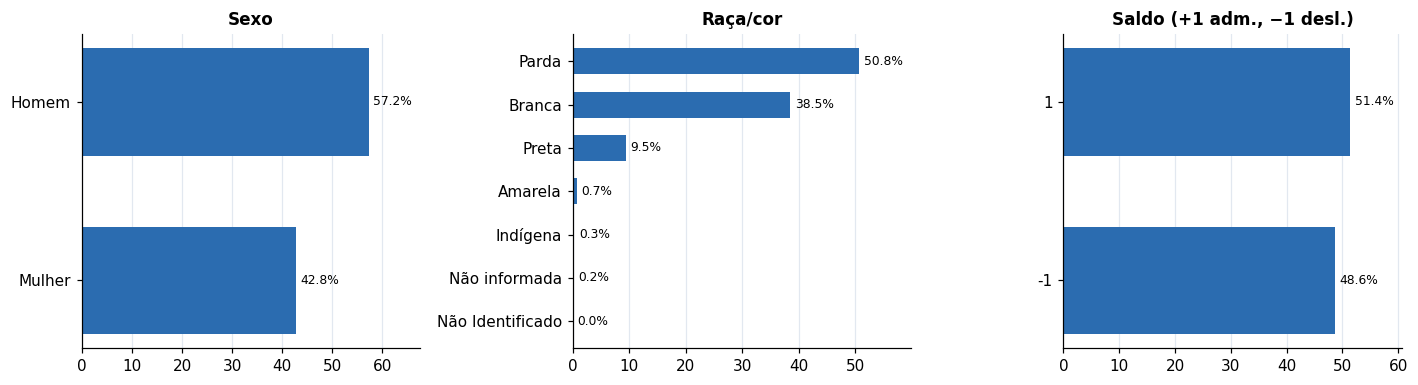

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, (col, nome, titulo) in zip(ax, [("sexo","sexo","Sexo"),("raçacor","raçacor","Raça/cor"),("saldomovimentação",None,"Saldo (+1 adm., −1 desl.)")]):
    t = freq(df[col], nome)["%"].sort_values()
    a.barh(t.index, t.values, color=AZUL, height=0.6)
    for y, v in enumerate(t.values): a.text(v + 0.8, y, f"{v:.1f}%", va="center", fontsize=8)
    a.set_title(titulo); a.set_xlim(0, t.max() * 1.18); a.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 5. Variáveis quantitativas

In [10]:
quant = ["idade", "horascontratuais", "salário"]
desc = df[quant].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
desc["assimetria"] = df[quant].skew()
desc

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,assimetria
idade,"4,302,251.00",33.08,11.50,14.00,17.00,18.00,24.00,31.00,41.00,55.00,63.00,97.00,0.68
horascontratuais,"4,307,569.00",42.31,5.43,0.00,20.00,30.00,44.00,44.00,44.00,44.00,48.00,60.00,-3.75
salário,"4,307,569.00","2,608.15","16,818.32",0.00,0.00,"1,341.19","1,738.25","2,030.00","2,480.44","4,525.42","10,500.00","27,841,398.00","1,071.71"


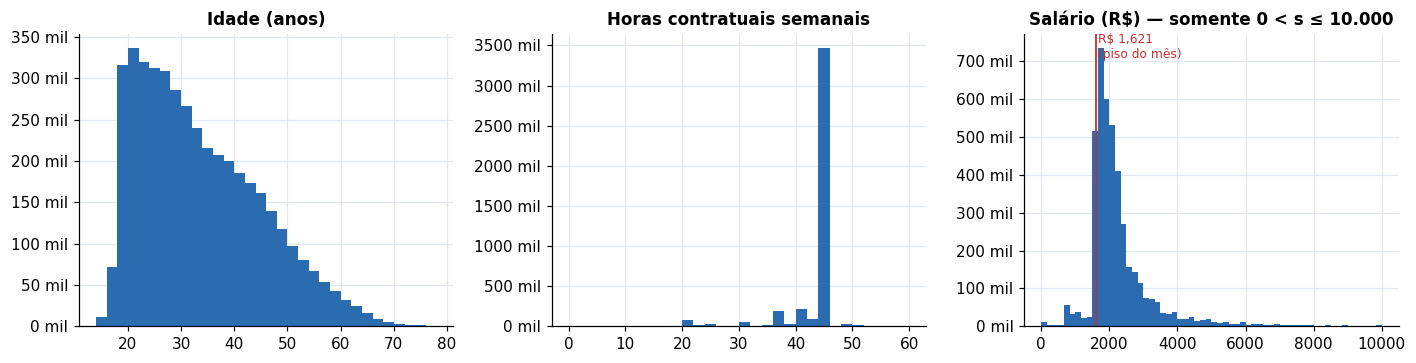

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(df["idade"].dropna(), bins=range(14, 80, 2), color=AZUL); ax[0].set_title("Idade (anos)")
ax[1].hist(df["horascontratuais"], bins=range(0, 62, 2), color=AZUL); ax[1].set_title("Horas contratuais semanais")
s = df.loc[(df["salário"] > 0) & (df["salário"] <= 10000), "salário"]
ax[2].hist(s, bins=60, color=AZUL); ax[2].set_title("Salário (R$) — somente 0 < s ≤ 10.000")
ax[2].axvline(PISO, color="#C53030", lw=1.2); ax[2].text(PISO + 40, ax[2].get_ylim()[1]*0.92, f"R$ {PISO:,.0f}\n(piso do mês)", color="#C53030", fontsize=8)
for a in ax: a.yaxis.set_major_formatter(lambda v, _: f"{v/1e3:.0f} mil")
plt.tight_layout(); plt.show()

### 5.1 O problema do salário
A média é puxada por poucos valores absurdos. Comparar média, mediana e o efeito de diferentes cortes ajuda a decidir **como definir a população** (truncar) ou **se usar o log**.

In [12]:
sal = df["salário"]
linhas = []
for nome, m in [("Todos", sal.notna()),
                ("s > 0", sal > 0),
                ("0 < s ≤ 20.000", (sal > 0) & (sal <= 20000)),
                ("0 < s ≤ 10.000", (sal > 0) & (sal <= 10000)),
                (f"{PISO:,.0f} ≤ s ≤ 20.000", (sal >= PISO) & (sal <= 20000))]:
    x = sal[m]
    linhas.append({"recorte": nome, "n": len(x), "% da base": len(x)/len(sal)*100,
                   "média": x.mean(), "mediana": x.median(), "desvio-padrão": x.std(),
                   "assimetria": x.skew(), "CV": x.std()/x.mean()})
pd.DataFrame(linhas).set_index("recorte")

,n,% da base,média,mediana,desvio-padrão,assimetria,CV
recorte,,,,,,,
Todos,4307569,100.00,"2,608.15","2,030.00","16,818.32","1,071.71",6.45
s > 0,4259127,98.88,"2,637.81","2,034.15","16,911.38","1,066.10",6.41
0 < s ≤ 20.000,4248112,98.62,"2,388.50","2,031.59","1,475.11",5.21,0.62
0 < s ≤ 10.000,4213132,97.81,"2,295.33","2,030.00","1,040.19",3.00,0.45
"1,621 ≤ s ≤ 20.000",4031324,93.59,"2,462.12","2,075.00","1,476.16",5.38,0.60


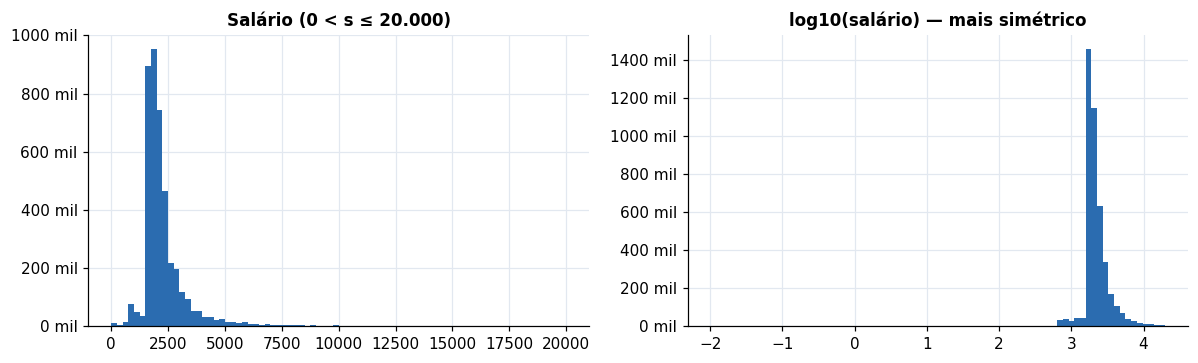

In [13]:
x = sal[(sal > 0) & (sal <= 20000)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(x, bins=80, color=AZUL); ax[0].set_title("Salário (0 < s ≤ 20.000)")
ax[1].hist(np.log10(x), bins=80, color=AZUL); ax[1].set_title("log10(salário) — mais simétrico")
for a in ax: a.yaxis.set_major_formatter(lambda v, _: f"{v/1e3:.0f} mil")
plt.tight_layout(); plt.show()

### 5.2 Unidade de pagamento do salário
Parte das linhas informa a remuneração por hora, dia ou outra unidade (`unidadesaláriocódigo`). Esta checagem mostra se `salário` já vem em base mensal (`salário` = `valorsaláriofixo`? valores compatíveis entre unidades?) ou se mistura escalas, o que explicaria valores extremos.

In [14]:
un = rotular(df["unidadesaláriocódigo"], "unidadesaláriocódigo")
t = df.assign(unidade=un).groupby("unidade").agg(
    n=("salário", "size"),
    salario_mediana=("salário", "median"),
    salario_p99=("salário", lambda s: s.quantile(.99)),
    fixo_mediana=("valorsaláriofixo", "median"),
    pct_salario_zero=("salário", lambda s: (s == 0).mean() * 100),
    pct_salario_diferente_do_fixo=("salário", lambda s: np.nan),
)
t["pct_salario_diferente_do_fixo"] = df.assign(unidade=un).groupby("unidade").apply(
    lambda g: (g["salário"] != g["valorsaláriofixo"]).mean() * 100, include_groups=False)
t["% da base"] = t["n"] / t["n"].sum() * 100
t.sort_values("n", ascending=False)

,n,salario_mediana,salario_p99,fixo_mediana,pct_salario_zero,pct_salario_diferente_do_fixo,% da base
unidade,,,,,,,
Mês,3955839,"2,030.00","10,344.78","2,030.00",0.15,0.00,91.83
Hora,266374,"2,145.00","13,200.00",10.19,0.94,99.04,6.18
Dia,34436,"2,400.00","30,000.00",80.00,0.76,99.24,0.80
Variavel,33603,0.00,0.00,0.00,100.00,0.00,0.78
Tarefa,11773,8.57,"2,105.34",8.57,35.18,0.00,0.27
Não Identificado,2298,0.00,"5,966.65",0.00,82.20,0.00,0.05
Semana,1944,"2,055.00","11,466.98",411.00,5.71,94.29,0.05
Quinzena,1302,"3,325.00","8,000.00","1,662.50",0.38,99.62,0.03


## 6. Profissão (CBO 2002)
O código de 6 dígitos identifica a ocupação; o **1º dígito** é o grande grupo (útil para ter poucas categorias).

In [15]:
cbo = abas["cbo2002ocupação"].copy(); cbo.columns = ["cod", "ocupação"]
cbo["cod"] = cbo["cod"].astype(str).str.zfill(6)
df["cbo"] = df["cbo2002ocupação"].str.zfill(6)
df = df.merge(cbo, left_on="cbo", right_on="cod", how="left").drop(columns="cod")
print(f"Ocupações distintas: {df['cbo'].nunique():,} | sem nome no dicionário: {df['ocupação'].isna().mean():.2%}")
top = df["ocupação"].value_counts(normalize=True).head(15).mul(100).round(2).rename("%").to_frame()
top

Ocupações distintas: 2,487 | sem nome no dicionário: 0.07%


,%
ocupação,
Faxineiro (Desativado em 2010),5.16
Alimentador de Linha de Producao,4.88
Vendedor de Comercio Varejista,4.51
"Auxiliar de Escritorio, em Geral",3.20
Assistente Administrativo,3.04
Servente de Obras,3.04
Operador de Caixa,2.87
Atendente de Lojas e Mercados,2.86
Auxiliar de Logistica,2.52


In [16]:
# Nomes dos grandes grupos: CBO 2002 (conferir com a fonte antes de usar no trabalho)
GG = {"0": "Forças armadas", "1": "Dirigentes", "2": "Profissionais das ciências e artes",
      "3": "Técnicos de nível médio", "4": "Serviços administrativos",
      "5": "Serviços e vendedores", "6": "Agropecuária", "7": "Produção industrial e construção",
      "8": "Produção contínua", "9": "Manutenção e reparação"}
df["grande_grupo"] = df["cbo"].str[0].map(GG)
df["mulher"] = (df["sexo"] == 3)

# Salário "razoável" apenas para esta análise exploratória (não define a população!)
ok = (df["salário"] > 0) & (df["salário"] <= 20000)
gg = (df.groupby("grande_grupo")
        .agg(n=("sexo", "size"), pct_mulheres=("mulher", "mean"))
        .join(df[ok].groupby("grande_grupo")["salário"].agg(["median", "mean"]).rename(columns={"median":"mediana_sal","mean":"média_sal"})))
gg["pct_base"] = gg["n"] / gg["n"].sum() * 100
gg["pct_mulheres"] *= 100
gg.sort_values("n", ascending=False)

,n,pct_mulheres,mediana_sal,média_sal,pct_base
grande_grupo,,,,,
Serviços e vendedores,1352538,54.82,"1,847.22","1,953.12",31.40
Produção industrial e construção,1059408,16.41,"2,250.60","2,419.01",24.59
Serviços administrativos,877154,60.12,"1,946.36","2,085.80",20.36
Técnicos de nível médio,310208,53.38,"2,314.62","2,925.16",7.20
Profissionais das ciências e artes,198104,59.85,"3,836.80","4,778.72",4.60
Agropecuária,189605,15.37,"1,874.36","2,075.04",4.40
Produção contínua,138945,26.90,"2,140.00","2,332.38",3.23
Manutenção e reparação,92697,6.27,"2,300.00","2,731.83",2.15
Dirigentes,88847,48.45,"3,500.00","4,998.61",2.06


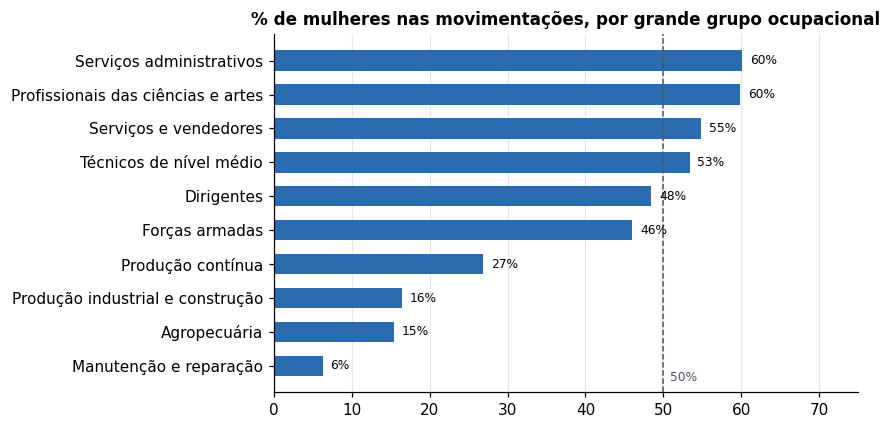

In [17]:
t = gg.sort_values("pct_mulheres")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(t.index, t["pct_mulheres"], color=AZUL, height=0.6)
ax.axvline(50, color="#4A5568", lw=1, ls="--"); ax.text(50.8, -0.45, "50%", fontsize=8, color="#4A5568")
for y, v in enumerate(t["pct_mulheres"]): ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=8)
ax.set_title("% de mulheres nas movimentações, por grande grupo ocupacional")
ax.set_xlim(0, 75); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()


### 6.1 Outliers do salário: boxplot (para decidir o teto)
População **provisória, sem teto**: já aplica só as regras aprovadas (unidade de pagamento Mês/Hora/Dia/Semana/Quinzena, salário > 0, horas > 0, idade informada).
Pergunta: acima de que valor um salário é *erro* e não apenas um salário alto?


In [18]:

UNID_OK = [1, 2, 3, 4, 5]   # 1 Hora, 2 Dia, 3 Semana, 4 Quinzena, 5 Mês (3 unidades sem escala mensal ficam de fora)
_m = (df["unidadesaláriocódigo"].isin(UNID_OK) & (df["salário"] > 0)
      & (df["horascontratuais"] > 0) & df["idade"].notna())
# só as colunas necessárias, para não duplicar a tabela inteira na memória
prov = df.loc[_m, ["salário", "valorsaláriofixo", "unidadesaláriocódigo", "horascontratuais",
                   "idade", "grande_grupo", "ocupação", "seção"]].copy()
del _m
s = prov["salário"]
print(f"População provisória (sem teto): {len(s):,} linhas ({len(s)/len(df):.2%} da base raw)")

q = s.quantile([.5, .9, .95, .99, .995, .999, .9999, 1]).rename("R$").to_frame()
q.index = ["mediana", "p90", "p95", "p99", "p99,5", "p99,9", "p99,99", "máximo"]
display(q)

q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
ls = np.log10(s); lq1, lq3 = ls.quantile([.25, .75]); liqr = lq3 - lq1
print(f"Q1 = R$ {q1:,.0f} | Q3 = R$ {q3:,.0f} | IQR = R$ {iqr:,.0f}")
print(f"Cerca superior de Tukey (Q3 + 1,5·IQR), escala linear: R$ {q3 + 1.5*iqr:,.0f}  -> {(s > q3 + 1.5*iqr).mean():.2%} das linhas acima")
print(f"Cerca superior de Tukey na escala log10:               R$ {10**(lq3 + 1.5*liqr):,.0f}  -> {(s > 10**(lq3 + 1.5*liqr)).mean():.2%} das linhas acima")
print(f"Cerca inferior de Tukey na escala log10:               R$ {10**(lq1 - 1.5*liqr):,.0f}  -> {(s < 10**(lq1 - 1.5*liqr)).mean():.2%} das linhas abaixo")

limiares = [10000, 15000, 20000, 25000, 30000, 50000, 100000, 1e6, 1e7]
tab = pd.DataFrame({"salário acima de (R$)": limiares, "linhas": [int((s > x).sum()) for x in limiares]})
tab["% da população provisória"] = tab["linhas"] / len(s) * 100
tab


População provisória (sem teto): 4,245,813 linhas (98.57% da base raw)


,R$
mediana,"2,035.00"
p90,"3,418.66"
p95,"4,567.41"
p99,"10,531.91"
"p99,5","15,000.00"
"p99,9","35,500.00"
"p99,99","470,765.58"
máximo,"27,841,398.00"


Q1 = R$ 1,750 | Q3 = R$ 2,499 | IQR = R$ 750
Cerca superior de Tukey (Q3 + 1,5·IQR), escala linear: R$ 3,624  -> 8.45% das linhas acima
Cerca superior de Tukey na escala log10:               R$ 4,267  -> 5.88% das linhas acima
Cerca inferior de Tukey na escala log10:               R$ 1,025  -> 2.51% das linhas abaixo


,salário acima de (R$),linhas,% da população provisória
0,"10,000.00",45973,1.08
1,"15,000.00",20328,0.48
2,"20,000.00",11006,0.26
3,"25,000.00",7319,0.17
4,"30,000.00",5366,0.13
5,"50,000.00",2911,0.07
6,"100,000.00",1940,0.05
7,"1,000,000.00",52,0.00
8,"10,000,000.00",1,0.00


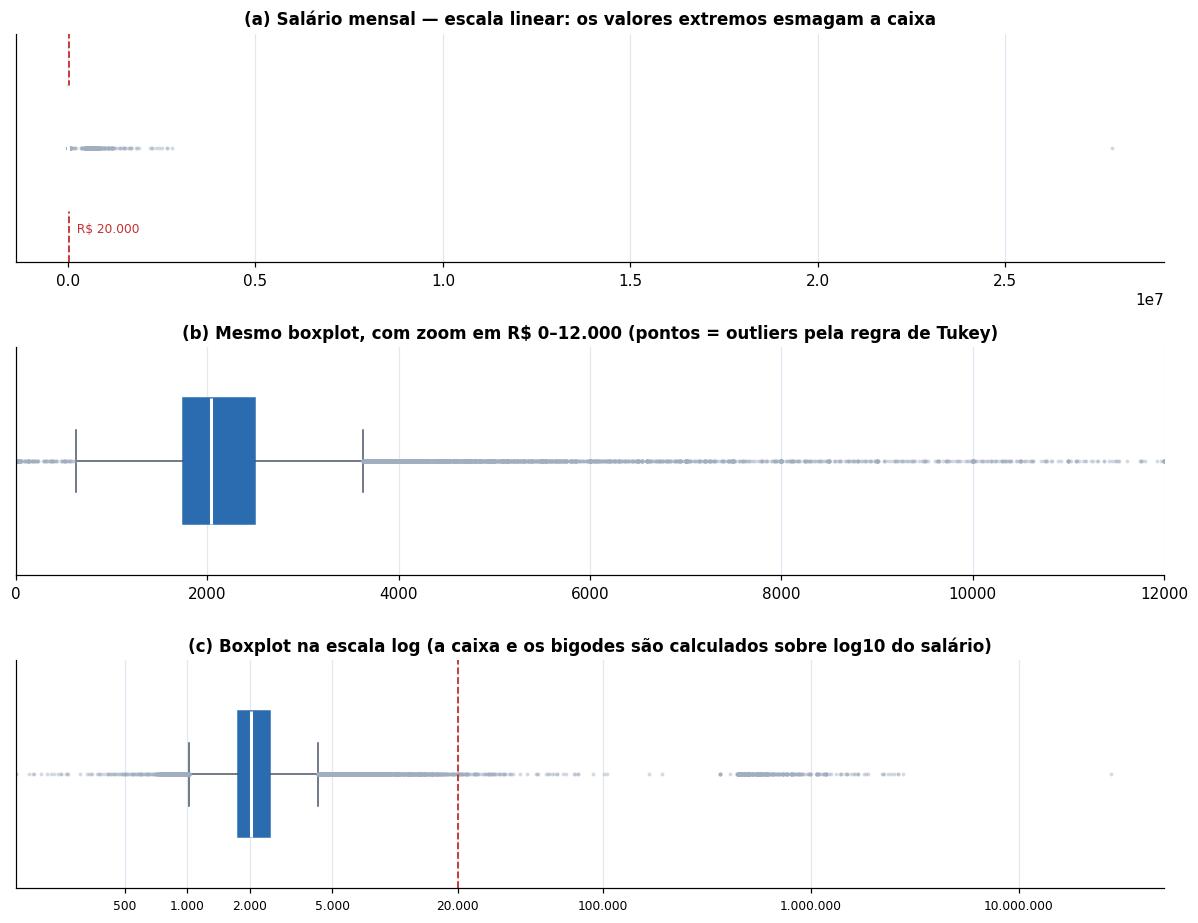

In [19]:

from matplotlib import cbook
rng = np.random.default_rng(1)

def stats_box(x, rotulo, max_pts=4000):
    """Estatísticas do boxplot (Tukey, 1,5·IQR) na população inteira; só os pontos desenhados são subamostrados."""
    st = cbook.boxplot_stats(np.asarray(x), whis=1.5, labels=[rotulo])[0]
    f = np.asarray(st["fliers"])
    if len(f) > max_pts:
        f = np.concatenate([rng.choice(f, max_pts - 500, replace=False), np.sort(f)[-500:]])   # os 500 maiores sempre aparecem
    st["fliers"] = f
    return st

ESTILO = dict(vert=False, patch_artist=True, showfliers=True, widths=0.55,
              boxprops=dict(facecolor=AZUL, edgecolor=AZUL), medianprops=dict(color="white", lw=2),
              whiskerprops=dict(color="#4A5568"), capprops=dict(color="#4A5568"),
              flierprops=dict(marker="o", markersize=2.5, markerfacecolor=CINZA, markeredgecolor="none", alpha=0.45))

fig, ax = plt.subplots(3, 1, figsize=(11, 8.5))
# (a) escala linear, população inteira
ax[0].bxp([stats_box(s, "")], **ESTILO); ax[0].set_title("(a) Salário mensal — escala linear: os valores extremos esmagam a caixa")
# (b) escala linear, zoom na região da caixa
ax[1].bxp([stats_box(s, "")], **ESTILO); ax[1].set_xlim(0, 12000)
ax[1].set_title("(b) Mesmo boxplot, com zoom em R$ 0–12.000 (pontos = outliers pela regra de Tukey)")
# (c) Tukey aplicado ao log10 do salário (mais adequado a dados assimétricos)
st = cbook.boxplot_stats(ls.to_numpy(), whis=1.5, labels=[""])[0]
f = np.asarray(st["fliers"]); st["fliers"] = np.concatenate([rng.choice(f, 3500, replace=False), np.sort(f)[-500:]]) if len(f) > 4000 else f
ax[2].bxp([st], **ESTILO)
marcas = [500, 1000, 2000, 5000, 20000, 100000, 1e6, 1e7]
ax[2].set_xticks(np.log10(marcas), [f"{m:,.0f}".replace(",", ".") for m in marcas], fontsize=8)
ax[2].set_xlim(np.log10(150), np.log10(5e7))
ax[2].set_title("(c) Boxplot na escala log (a caixa e os bigodes são calculados sobre log10 do salário)")
for a in ax:
    a.set_yticks([]); a.grid(axis="y", visible=False)
for a, x in zip(ax, [20000, 20000, np.log10(20000)]):
    a.axvline(x, color="#C53030", lw=1.2, ls="--")
ax[0].text(20000, 0.62, "  R$ 20.000", color="#C53030", fontsize=8, va="bottom")
plt.tight_layout(); plt.show()


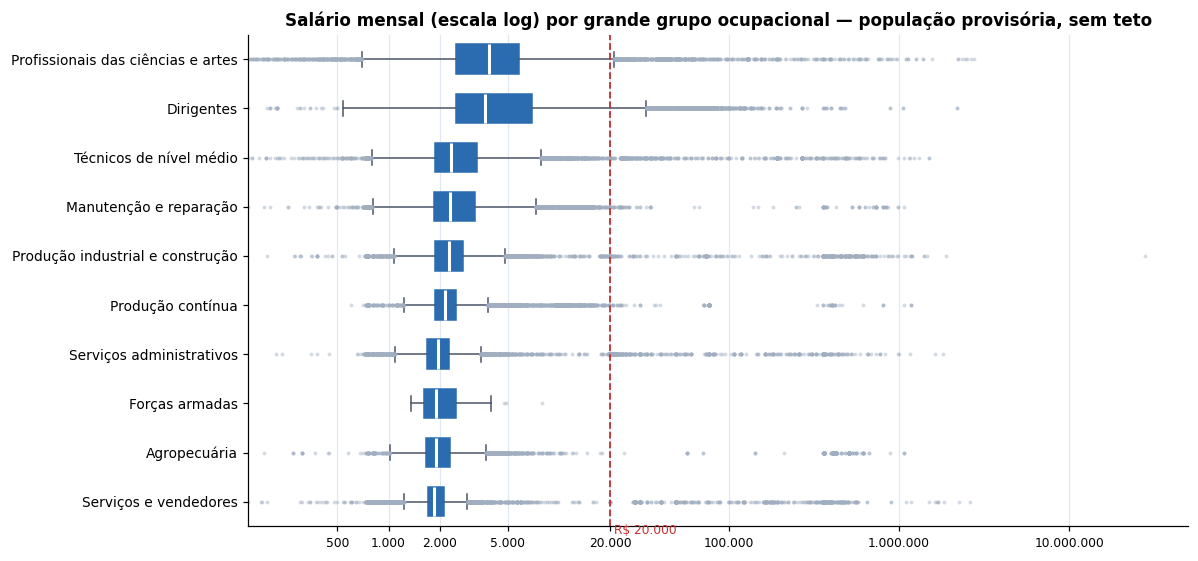

,n,mediana,p99,pct_acima_20k,pct_acima_25k
grande_grupo,,,,,
Serviços e vendedores,1324616,"1,848.00","4,179.67",0.04,0.04
Agropecuária,170129,"1,892.00","5,002.72",0.34,0.33
Forças armadas,63,"1,894.69","6,057.34",0.00,0.00
Serviços administrativos,874693,"1,947.68","5,927.01",0.05,0.04
Produção contínua,138609,"2,140.14","6,002.82",0.08,0.07
Produção industrial e construção,1054319,"2,251.00","5,500.00",0.04,0.04
Manutenção e reparação,92122,"2,300.00","8,058.98",0.08,0.06
Técnicos de nível médio,307826,"2,319.68","11,967.76",0.19,0.14
Dirigentes,88190,"3,692.50","44,730.53",6.36,4.00


In [20]:

# Mesma pergunta por grande grupo ocupacional: o que é "outlier" no geral pode ser normal dentro de um cargo
g = prov   # já contém grande_grupo
ordem = g.groupby("grande_grupo")["salário"].median().sort_values().index.tolist()
sts = [stats_box(np.log10(g.loc[g["grande_grupo"] == o, "salário"]), o, max_pts=1500) for o in ordem]
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.bxp(sts, positions=range(len(sts)), **{**ESTILO, "widths": 0.6})
ax.set_yticks(range(len(ordem)), ordem, fontsize=9); ax.grid(axis="y", visible=False)
ax.set_xticks(np.log10(marcas), [f"{m:,.0f}".replace(",", ".") for m in marcas], fontsize=8)
ax.set_xlim(np.log10(150), np.log10(5e7))
ax.axvline(np.log10(20000), color="#C53030", lw=1.2, ls="--"); ax.text(np.log10(20000), -0.65, " R$ 20.000", color="#C53030", fontsize=8)
ax.set_title("Salário mensal (escala log) por grande grupo ocupacional — população provisória, sem teto")
plt.tight_layout(); plt.show()

res = g.groupby("grande_grupo")["salário"].agg(
    n="size", mediana="median", p99=lambda x: x.quantile(.99),
    pct_acima_20k=lambda x: (x > 20000).mean() * 100, pct_acima_25k=lambda x: (x > 25000).mean() * 100).sort_values("mediana")
res


In [21]:

print("% acima de R$ 20.000 por unidade de pagamento (a conversão para mês pode inflar o valor):")
un_lbl = rotular(prov["unidadesaláriocódigo"], "unidadesaláriocódigo")
display(prov.assign(unidade=un_lbl).groupby("unidade")["salário"].agg(
    n="size", mediana="median", pct_acima_20k=lambda x: (x > 20000).mean() * 100))

print("\n15 maiores salários da população provisória:")
top = prov.nlargest(15, "salário")[["salário", "valorsaláriofixo", "unidadesaláriocódigo", "horascontratuais", "idade", "ocupação"]].copy()
top["unidade"] = rotular(top["unidadesaláriocódigo"], "unidadesaláriocódigo")
top["setor"] = rotular(prov.loc[top.index, "seção"], "seção").str[:30]
top.drop(columns="unidadesaláriocódigo")


% acima de R$ 20.000 por unidade de pagamento (a conversão para mês pode inflar o valor):


,n,mediana,pct_acima_20k
unidade,,,
Dia,34152,"2,424.90",1.08
Hora,263548,"2,151.60",0.79
Mês,3944985,"2,031.57",0.22
Quinzena,1295,"3,328.00",0.08
Semana,1833,"2,055.00",0.00



15 maiores salários da população provisória:


,salário,valorsaláriofixo,horascontratuais,idade,ocupação,unidade,setor
2954342,"27,841,398.00","126,551.81",44.00,40.00,Pintor de Obras,Hora,Construção
667532,"2,779,416.00","13,897.08",40.00,38.00,Professor de Disciplinas Pedagogicas no Ensino...,Hora,Educação
2387852,"2,640,193.50","12,000.88",44.00,33.00,Professor de Disciplinas Pedagogicas no Ensino...,Hora,Educação
1654719,"2,627,641.00","2,627,641.00",44.00,19.00,Vendedor de Comercio Varejista,Mês,"Comércio, Reparação de Veículo"
2758007,"2,509,350.75","11,406.14",44.00,29.00,Professor de Disciplinas Pedagogicas no Ensino...,Hora,Educação
3719184,"2,438,664.75","11,084.84",44.00,27.00,Analista de Desenvolvimento de Sistemas,Hora,Indústrias de Transformação
3847218,"2,353,425.75","10,697.39",44.00,35.00,Professor de Disciplinas Pedagogicas no Ensino...,Hora,Educação
3442488,"2,247,090.00","2,247,090.00",44.00,65.00,Porteiro de Edificios,Mês,Atividades Administrativas e S
3827692,"2,228,223.75","10,128.29",44.00,30.00,Professor de Disciplinas Pedagogicas no Ensino...,Hora,Educação
622667,"2,200,000.00","10,000.00",44.00,56.00,Gerente de Producao e Operacoes,Hora,Indústrias Extrativas



#### Onde está a lacuna? Histograma do salário (eixo Y em escala log)
O boxplot mostra *quais pontos são raros*, mas não separa salário alto real de erro. A contagem por faixa mostra isso melhor.


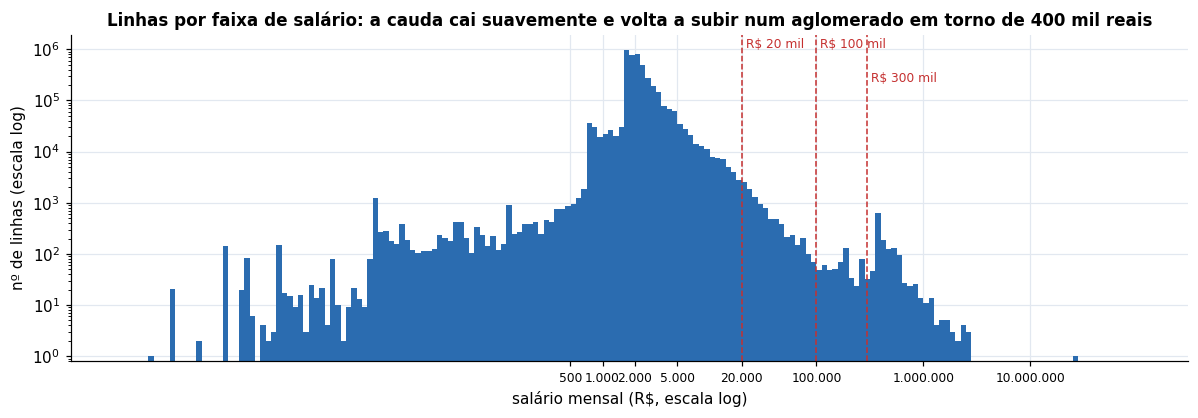

,linhas,% da população provisória
salário,,
"(0.0, 100.0]",7068,0.17
"(100.0, 300.0]",3365,0.08
"(300.0, 500.0]",2983,0.07
"(500.0, 600.0]",1727,0.04
"(600.0, 800.0]",39081,0.92
"(800.0, 1621.0]",423832,9.98
"(1621.0, 20000.0]",3756751,88.48
"(20000.0, 100000.0]",9066,0.21
"(100000.0, 300000.0]",562,0.01


Unidade Hora — valor da hora (R$/h): mediana 10.2 | p99 81.3 | % com valor/hora > R$ 500: 0.70% (1,833 linhas)
Unidade Mês — salário < R$ 500: 6,480 linhas (0.16%) | > R$ 100.000: 189 linhas


In [22]:

fig, ax = plt.subplots(figsize=(11, 3.9))
ax.hist(np.log10(s), bins=np.arange(-1.5, 8.01, 0.05), color=AZUL)
ax.set_yscale("log"); ax.set_ylim(0.8, None)
ax.set_xticks(np.log10(marcas), [f"{m:,.0f}".replace(",", ".") for m in marcas], fontsize=8)
for x, lab, yf in [(20000, "R$ 20 mil", 0.55), (100000, "R$ 100 mil", 0.55), (300000, "R$ 300 mil", 0.12)]:
    ax.axvline(np.log10(x), color="#C53030", lw=1, ls="--"); ax.text(np.log10(x), ax.get_ylim()[1] * yf, " " + lab, color="#C53030", fontsize=8)
ax.set_xlabel("salário mensal (R$, escala log)"); ax.set_ylabel("nº de linhas (escala log)")
ax.set_title("Linhas por faixa de salário: a cauda cai suavemente e volta a subir num aglomerado em torno de 400 mil reais")
plt.tight_layout(); plt.show()

faixas = [0, 100, 300, 500, 600, 800, 1621, 20000, 100000, 300000, 1e9]
tf = pd.cut(s, faixas).value_counts().sort_index().to_frame("linhas")
tf["% da população provisória"] = tf["linhas"] / len(s) * 100
display(tf)

# Plausibilidade dentro da unidade 'Hora': valor da hora muito acima do usual sugere salário mensal digitado no campo da hora
h = prov[prov["unidadesaláriocódigo"] == 1]
print("Unidade Hora — valor da hora (R$/h): mediana {:.1f} | p99 {:.1f} | % com valor/hora > R$ 500: {:.2f}% ({:,} linhas)".format(
    h["valorsaláriofixo"].median(), h["valorsaláriofixo"].quantile(.99), (h["valorsaláriofixo"] > 500).mean() * 100, (h["valorsaláriofixo"] > 500).sum()))
m = prov[prov["unidadesaláriocódigo"] == 5]
print(f"Unidade Mês — salário < R$ 500: {(m['salário'] < 500).sum():,} linhas ({(m['salário'] < 500).mean():.2%}) | > R$ 100.000: {(m['salário'] > 100000).sum():,} linhas")


## 7. Preparação de colunas auxiliares (em memória; o arquivo original não é tocado)
Rótulos legíveis e indicadores. **Atenção:** `ok` (0 < salário ≤ 20.000) é só um filtro *exploratório* para resumir salários; a definição da população do trabalho ainda será decidida.

In [23]:
df["adm"]       = df["saldomovimentação"] == 1
df["sexo_r"]    = rotular(df["sexo"], "sexo")
df["raca"]      = rotular(df["raçacor"], "raçacor")
df["instrucao"] = rotular(df["graudeinstrução"], "graudeinstrução")
df["uf_nome"]   = rotular(df["uf"], "uf")
df["setor"]     = rotular(df["seção"], "seção")
df["tam_estab"] = rotular(df["tamestabjan"], "tamestabjan")

# Ordem lógica de escolaridade (rank ordinal)
ORD_INSTR = ["Analfabeto", "Até 5ª Incompleto", "5ª Completo Fundamental", "6ª a 9ª Fundamental",
             "Fundamental Completo", "Médio Incompleto", "Médio Completo", "Superior Incompleto",
             "Superior Completo", "Pós-Graduação completa", "Mestrado", "Doutorado"]
df["escol_ord"] = df["instrucao"].map({n: i + 1 for i, n in enumerate(ORD_INSTR)})

df["faixa_idade"] = pd.cut(df["idade"], [13, 17, 24, 29, 39, 49, 59, 120],
                           labels=["14–17", "18–24", "25–29", "30–39", "40–49", "50–59", "60+"])
ok = (df["salário"] > 0) & (df["salário"] <= 20000)

CINZA_ESC, LARANJA = "#4A5568", "#DD6B20"     # Homem = azul, Mulher = laranja (ordem fixa)
COR_SEXO = {"Homem": AZUL, "Mulher": LARANJA}

def resumo(chave):
    g = df.groupby(chave, observed=True)
    t = g.agg(n=("adm", "size"), pct_mulheres=("mulher", "mean"),
              pct_admissoes=("adm", "mean"), saldo_liquido=("saldomovimentação", "sum"))
    t["pct_base"] = t["n"] / t["n"].sum() * 100
    t[["pct_mulheres", "pct_admissoes"]] *= 100
    t["mediana_sal"] = df[ok].groupby(chave, observed=True)["salário"].median()
    return t

def barh(serie, titulo, fmt="{:.1f}", cor=AZUL, ref=None, ax=None, polaridade=False):
    ax = ax or plt.subplots(figsize=(7, 0.32 * len(serie) + 1))[1]
    cores = [AZUL if v >= 0 else LARANJA for v in serie.values] if polaridade else cor
    ax.barh(serie.index.astype(str), serie.values, color=cores, height=0.65)
    for y, v in enumerate(serie.values):
        ax.text(v + (abs(serie.max()) * 0.01 if v >= 0 else -abs(serie.max()) * 0.01), y, fmt.format(v),
                va="center", ha="left" if v >= 0 else "right", fontsize=7.5)
    if ref is not None: ax.axvline(ref, color=CINZA_ESC, lw=1, ls="--")
    ax.set_title(titulo); ax.grid(axis="y", visible=False)
    ax.margins(x=0.12)
    return ax

print("Colunas auxiliares criadas; linhas:", len(df))

Colunas auxiliares criadas; linhas: 4307569


## 8. Visão geral: colunas constantes e variáveis auxiliares
Quais colunas realmente variam? (as constantes não servem para análise)

In [24]:
nun = df.nunique().sort_values()
print("Colunas com 1 só valor (não informativas):", list(nun[nun == 1].index))
nun.to_frame("valores distintos").T

Colunas com 1 só valor (não informativas): ['competênciamov', 'indicadordeforadoprazo', 'competênciadec', 'tamestabjan', 'tam_estab']


,competênciamov,indicadordeforadoprazo,competênciadec,tamestabjan,tam_estab,indicadoraprendiz,sexo,saldomovimentação,mulher,sexo_r,adm,origemdainformação,tipoestabelecimento,indtrabintermitente,indtrabparcial,tipoempregador,região,tipodedeficiência,categoria,faixa_idade,...,raçacor,unidadesaláriocódigo,grande_grupo,tipomovimentação,graudeinstrução,instrucao,escol_ord,setor,seção,uf,uf_nome,idade,subclasse,ocupação,cbo2002ocupação,cbo,horascontratuais,município,valorsaláriofixo,salário
valores distintos,1,1,1,1,1,2,2,2,2,2,2,2,3,3,3,3,6,7,7,7,...,7,8,10,11,12,12,12,22,22,28,28,82,1304,2453,2487,2487,3246,5486,268910,272459


In [25]:
for col, nome in [("tipoempregador", "tipoempregador"), ("categoria", None), ("tipodedeficiência", None),
                  ("indicadoraprendiz", None), ("indtrabparcial", None), ("indtrabintermitente", None),
                  ("tipoestabelecimento", None)]:
    print(f"\n{col.upper()}"); display(freq(df[col], nome))


TIPOEMPREGADOR


,n,%
tipoempregador,,
CNPJ RAIZ,4193905,97.36
CPF,113662,2.64
(sem rótulo),2,0.00



CATEGORIA


,n,%
categoria,,
101,3934789,91.35
106,171853,3.99
103,105916,2.46
111,62202,1.44
105,30387,0.71
102,2008,0.05
999,414,0.01



TIPODEDEFICIÊNCIA


,n,%
tipodedeficiência,,
0,4283695,99.45
1,8488,0.20
4,4660,0.11
3,4512,0.10
2,4429,0.10
5,918,0.02
6,867,0.02


... (4 outputs left out)


INDTRABINTERMITENTE


,n,%
indtrabintermitente,,
0,4244953,98.55
1,62202,1.44
9,414,0.01



TIPOESTABELECIMENTO


,n,%
tipoestabelecimento,,
1,4107272,95.35
3,111655,2.59
4,88642,2.06


In [26]:
print("TAMANHO DO ESTABELECIMENTO (faixa de empregados em janeiro)")
display(freq(df["tam_estab"]).sort_index())

TAMANHO DO ESTABELECIMENTO (faixa de empregados em janeiro)


,n,%
tam_estab,,
Ignorado,4307569,100.00


## 9. Geografia (UF e municípios)
`pct_mulheres`, `pct_admissoes` e `saldo_liquido` (admissões − desligamentos) por UF. Salário mediano calculado com o filtro exploratório `ok`.

In [27]:
uf = resumo("uf_nome").sort_values("n", ascending=False)
uf

,n,pct_mulheres,pct_admissoes,saldo_liquido,pct_base,mediana_sal
uf_nome,,,,,,
São Paulo,1374823,46.47,50.71,19391,31.92,"2,170.07"
Minas gerais,460818,42.12,50.88,8102,10.70,"1,866.00"
Paraná,317780,44.59,50.91,5800,7.38,"2,150.00"
Rio de Janeiro,295635,43.48,51.57,9285,6.86,"1,907.42"
Santa Catarina,267298,44.89,51.33,7086,6.21,"2,250.00"
Rio Grande do Sul,246445,46.77,49.40,-2937,5.72,"2,013.00"
Bahia,169214,37.12,52.84,9626,3.93,"1,723.00"
Goiás,157597,40.04,50.10,307,3.66,"1,801.00"
Pernambuco,122749,34.98,55.45,13371,2.85,"1,738.00"


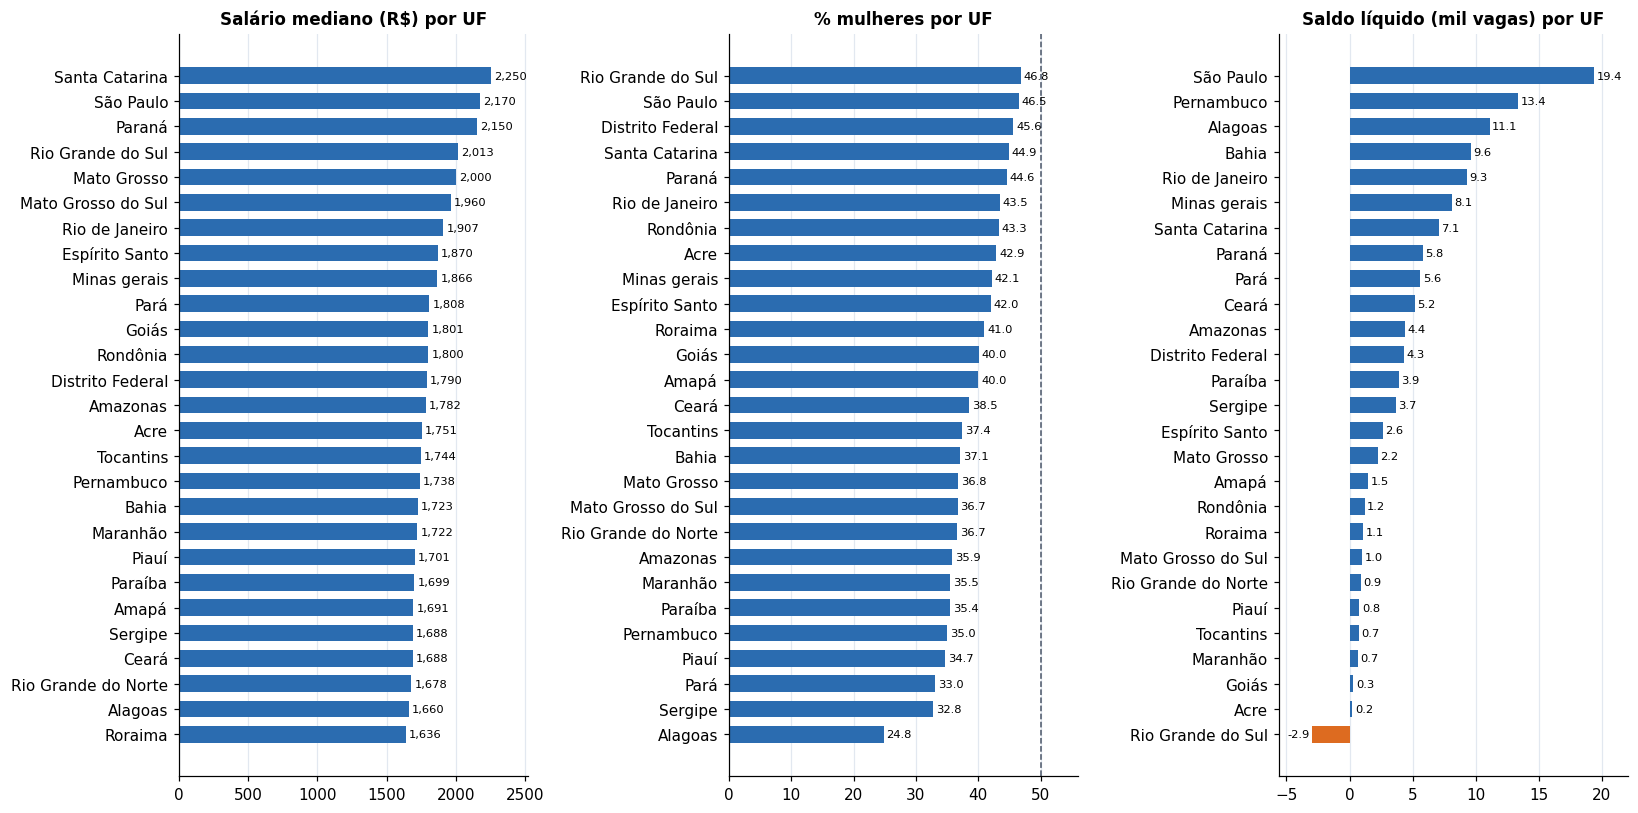

In [28]:
uf_g = uf[uf["n"] >= 1000]   # exclui "Não identificado" (521 linhas) dos gráficos
fig, ax = plt.subplots(1, 3, figsize=(15, 7.5))
barh(uf_g["mediana_sal"].sort_values(), "Salário mediano (R$) por UF", "{:,.0f}", ax=ax[0])
barh(uf_g["pct_mulheres"].sort_values(), "% mulheres por UF", "{:.1f}", ref=50, ax=ax[1])
barh((uf_g["saldo_liquido"] / 1e3).sort_values(), "Saldo líquido (mil vagas) por UF", "{:.1f}", ax=ax[2], polaridade=True)
plt.tight_layout(); plt.show()

In [29]:
mun = abas["município"].copy(); mun.columns = ["cod", "nome"]; mun["cod"] = mun["cod"].astype(str)
top_mun = df["município"].astype(str).value_counts().head(10).to_frame("n")
top_mun["%"] = top_mun["n"] / len(df) * 100
top_mun["município"] = [mun.set_index("cod")["nome"].get(c, "(sem rótulo)") for c in top_mun.index]
print(f"Municípios distintos: {df['município'].nunique():,} | 10 maiores concentram {top_mun['%'].sum():.1f}% das movimentações")
top_mun

Municípios distintos: 5,486 | 10 maiores concentram 27.5% das movimentações


,n,%,município
município,,,
355030,496122,11.52,Sp-Sao Paulo
330455,157625,3.66,Rj-Rio de Janeiro
310620,95975,2.23,Mg-Belo Horizonte
410690,88216,2.05,Pr-Curitiba
530010,78835,1.83,Df-Brasilia
230440,61254,1.42,Ce-Fortaleza
520870,52813,1.23,Go-Goiania
350570,51959,1.21,Sp-Barueri
130260,50980,1.18,Am-Manaus


## 10. Setor econômico do empregador (CNAE — seção)

In [30]:
st = resumo("setor").sort_values("n", ascending=False)
st

,n,pct_mulheres,pct_admissoes,saldo_liquido,pct_base,mediana_sal
setor,,,,,,
"Comércio, Reparação de Veículos Automotores e Motocicletas",1005835,48.02,50.78,15697,23.35,"1,970.00"
Atividades Administrativas e Serviços Complementares,788422,49.17,51.17,18386,18.30,"1,929.40"
Indústrias de Transformação,610624,34.25,51.29,15744,14.18,"2,150.60"
Construção,405012,8.37,51.17,9468,9.40,"2,404.60"
Alojamento e Alimentação,282961,59.57,51.87,10581,6.57,"1,884.34"
"Transporte, Armazenagem e Correio",250306,24.68,52.64,13240,5.81,"2,178.00"
Saúde Humana e Serviços Sociais,214809,77.90,53.59,15403,4.99,"1,982.35"
"Agricultura, Pecuária, Produção Florestal, Pesca e AqÜIcultura",184161,19.99,48.81,-4381,4.28,"1,942.11"
"Atividades Profissionais, Científicas e Técnicas",159710,45.50,52.05,6540,3.71,"2,165.27"


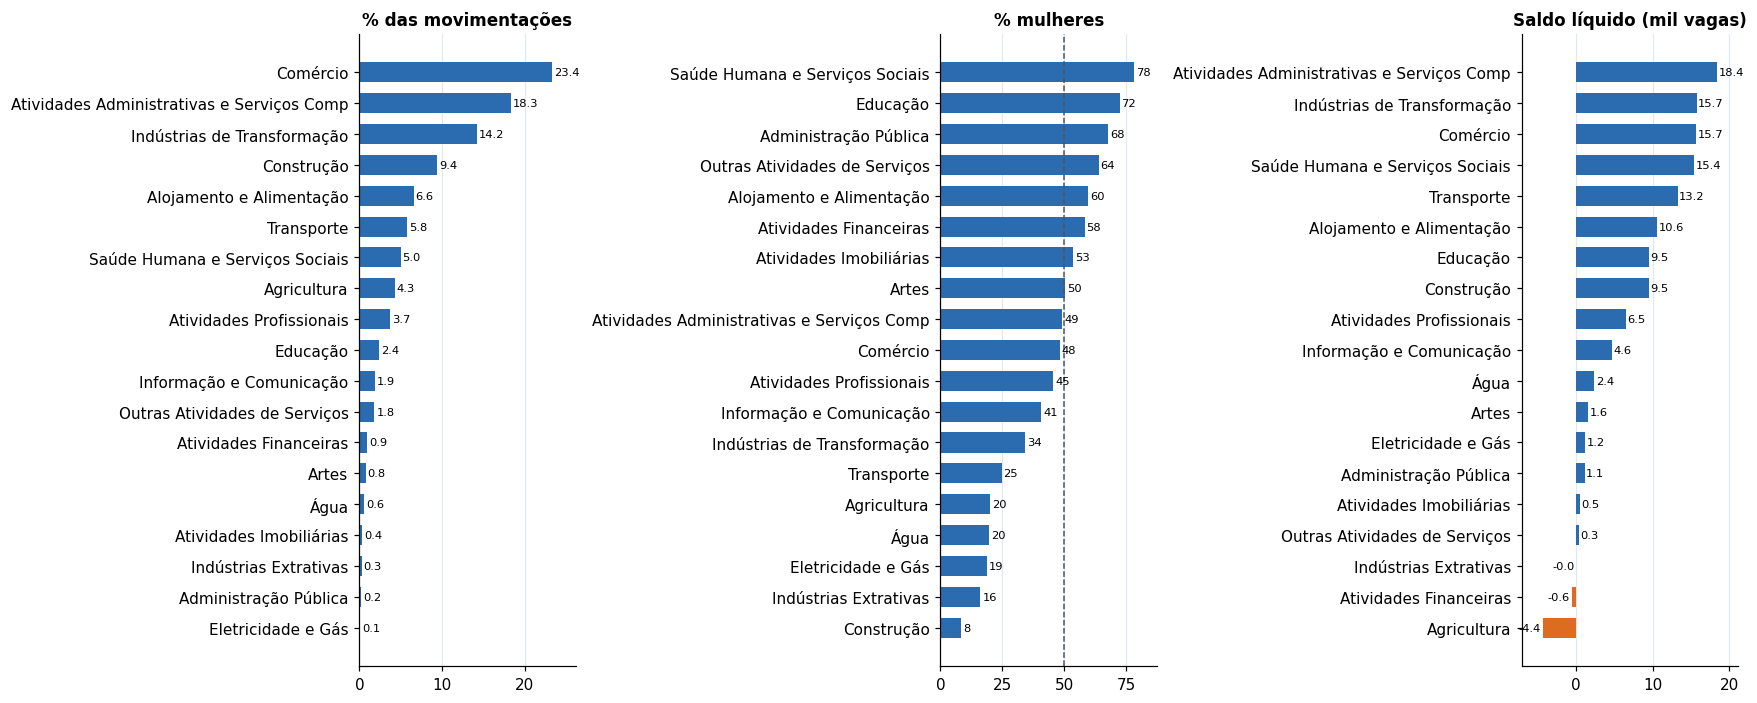

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(16, 6.5))
s = st[st["n"] >= 1000].copy(); s.index = [i.split(",")[0][:42] for i in s.index]   # só setores com n ≥ 1.000; nome curto
barh(s["pct_base"].sort_values(), "% das movimentações", "{:.1f}", ax=ax[0])
barh(s["pct_mulheres"].sort_values(), "% mulheres", "{:.0f}", ref=50, ax=ax[1])
barh((s["saldo_liquido"] / 1e3).sort_values(), "Saldo líquido (mil vagas)", "{:.1f}", ax=ax[2], polaridade=True)
plt.tight_layout(); plt.show()

## 11. Dinâmica: admissões × desligamentos
O saldo líquido do mês = admissões − desligamentos. Qual grupo contratou mais do que demitiu?

In [32]:
print(f"Admissões: {df['adm'].sum():,} | Desligamentos: {(~df['adm']).sum():,} | Saldo líquido do mês: {df['saldomovimentação'].sum():+,}")
tipos = (df.assign(tipo=rotular(df["tipomovimentação"], "tipomovimentação"))
           .query("not adm")["tipo"].value_counts(normalize=True).mul(100).round(2).rename("% dos desligamentos"))
tipos.to_frame()

Admissões: 2,214,437 | Desligamentos: 2,093,132 | Saldo líquido do mês: +121,305


,% dos desligamentos
tipo,
Desligamento por demissão sem justa causa,42.30
Desligamento a pedido,36.54
Término contrato trabalho prazo determinado,16.68
Desligamento por demissão com justa causa,3.09
Desligamento por Acordo entre empregado e empregador,0.95
Desligamento por morte,0.29
Desligamento de Tipo Ignorado,0.13
Desligamento por aposentadoria,0.02
Culpa Recíproca,0.00


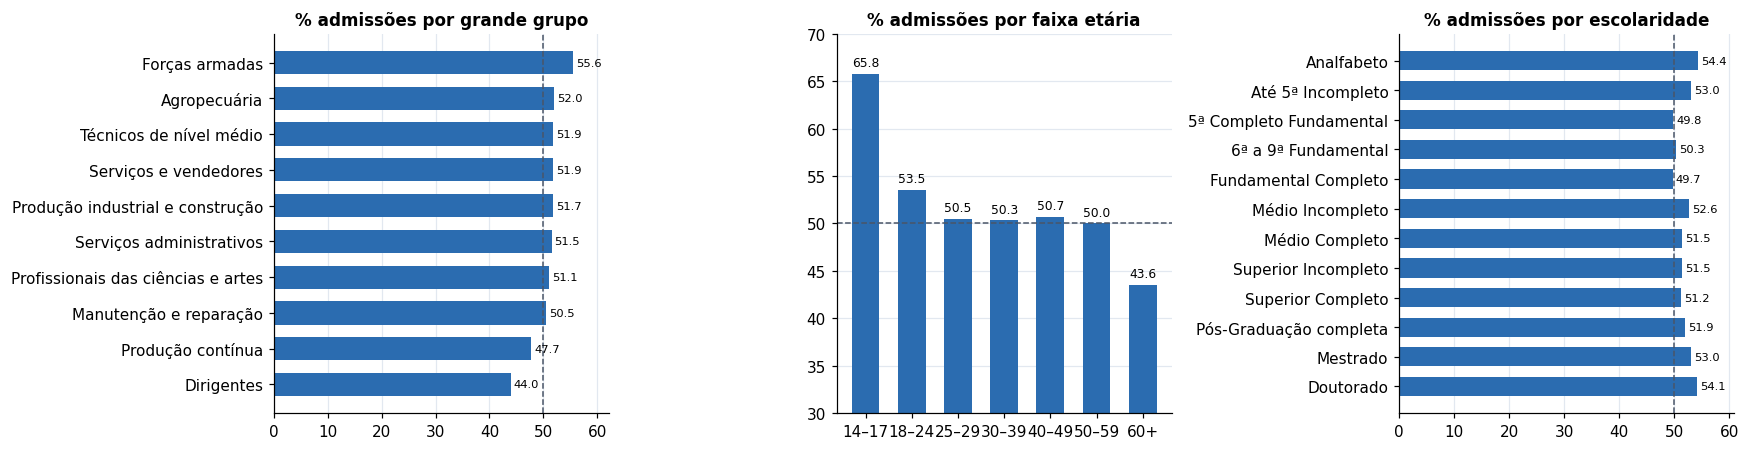

In [33]:
gg = resumo("grande_grupo").sort_values("pct_admissoes")
fx = resumo("faixa_idade")
ins = resumo(df["instrucao"].astype(pd.CategoricalDtype(ORD_INSTR, ordered=True)))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
barh(gg["pct_admissoes"], "% admissões por grande grupo", "{:.1f}", ref=50, ax=ax[0])
ax[1].bar(fx.index.astype(str), fx["pct_admissoes"], color=AZUL, width=0.6); ax[1].axhline(50, color=CINZA_ESC, ls="--", lw=1)
ax[1].set_title("% admissões por faixa etária"); ax[1].set_ylim(30, 70); ax[1].grid(axis="x", visible=False)
for x, v in enumerate(fx["pct_admissoes"]): ax[1].text(x, v + 0.8, f"{v:.1f}", ha="center", fontsize=8)
barh(ins["pct_admissoes"].dropna().iloc[::-1], "% admissões por escolaridade", "{:.1f}", ref=50, ax=ax[2])
plt.tight_layout(); plt.show()

## 12. Idade

In [34]:
fx

,n,pct_mulheres,pct_admissoes,saldo_liquido,pct_base,mediana_sal
faixa_idade,,,,,,
14–17,83761,47.25,65.78,26437,1.95,"1,142.33"
18–24,1129446,44.82,53.54,79856,26.25,"1,900.00"
25–29,749277,42.25,50.48,7177,17.42,"2,042.96"
30–39,1129349,42.06,50.33,7537,26.25,"2,113.00"
40–49,776331,43.06,50.68,10561,18.04,"2,156.00"
50–59,339794,40.71,50.01,94,7.90,"2,134.00"
60+,94293,31.43,43.56,-12151,2.19,"2,138.08"


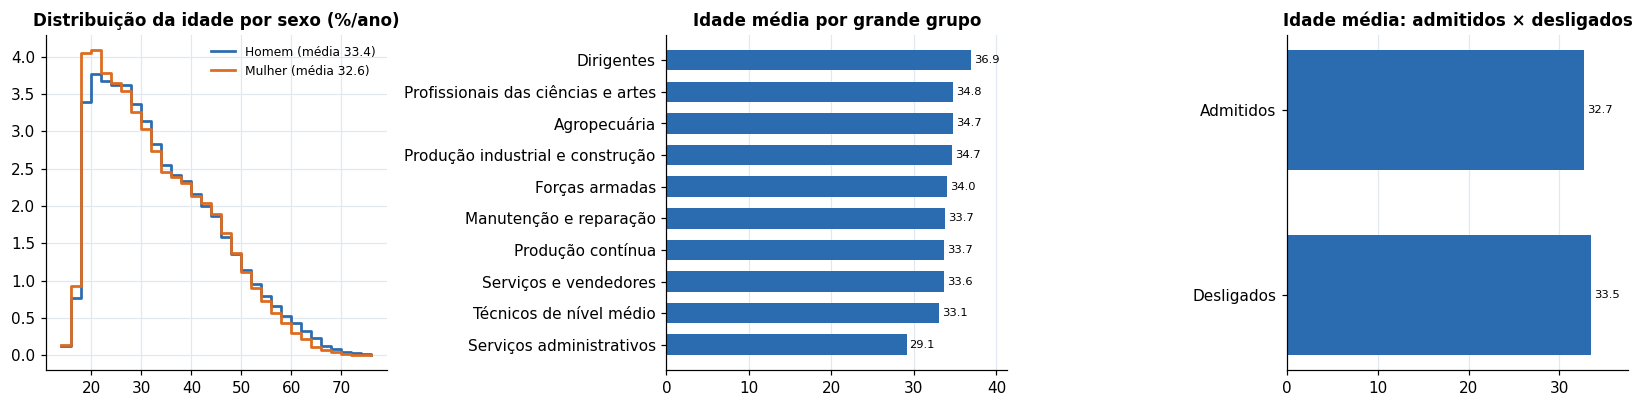

Aprendizes — idade:


,count,mean,std,min,25%,50%,75%,max
idade,"105,310.00",18.00,2.19,14.00,16.00,18.00,19.00,68.00


In [35]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for sx in ["Homem", "Mulher"]:
    x = df.loc[df["sexo_r"] == sx, "idade"].dropna()
    c, b = np.histogram(x, bins=range(14, 80, 2), density=True)
    ax[0].step(b[:-1], c * 100, where="post", color=COR_SEXO[sx], lw=1.8, label=f"{sx} (média {x.mean():.1f})")
ax[0].set_title("Distribuição da idade por sexo (%/ano)"); ax[0].legend(frameon=False, fontsize=8)
x = df.groupby("grande_grupo")["idade"].mean().sort_values()
barh(x, "Idade média por grande grupo", "{:.1f}", ax=ax[1])
x = df.groupby("adm")["idade"].mean().rename({True: "Admitidos", False: "Desligados"})
barh(x, "Idade média: admitidos × desligados", "{:.1f}", ax=ax[2])
plt.tight_layout(); plt.show()
print("Aprendizes — idade:"); display(df.loc[df["indicadoraprendiz"] == 1, "idade"].describe().to_frame().T)

## 13. Jornada de trabalho (horas contratuais)

In [36]:
h = df["horascontratuais"]
print("Valores mais frequentes de horas semanais:")
display(h.value_counts(normalize=True).head(8).mul(100).round(2).rename("%").to_frame())
df["faixa_horas"] = pd.cut(h, [-1, 19, 29, 35, 40, 43, 44, 60], labels=["<20", "20–29", "30–35", "36–40", "41–43", "44", ">44"])
hr = resumo("faixa_horas"); hr

Valores mais frequentes de horas semanais:


,%
horascontratuais,
44.00,79.66
40.00,4.66
36.00,4.30
20.00,1.70
30.00,1.26
42.00,0.93
48.00,0.62
45.00,0.51


,n,pct_mulheres,pct_admissoes,saldo_liquido,pct_base,mediana_sal
faixa_horas,,,,,,
<20,33215,54.48,54.23,2813,0.77,"1,033.40"
20–29,130485,59.87,54.60,11995,3.03,921.25
30–35,80647,65.23,51.71,2757,1.87,"1,621.00"
36–40,422988,57.63,52.21,18686,9.82,"2,022.00"
41–43,81836,47.53,51.69,2764,1.90,"2,083.99"
44,3455449,39.68,51.20,82821,80.22,"2,070.89"
>44,102949,38.57,49.74,-531,2.39,"1,900.00"


## 14. Salário — comparações e desigualdades
Todas as medianas usam o filtro exploratório `ok` (0 < s ≤ 20.000).

/tmp/ipykernel_58633/2707111872.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = a.boxplot(dados, labels=[str(o)[:18] for o in ordem], showfliers=False, patch_artist=True, widths=0.6,


/tmp/ipykernel_58633/2707111872.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = a.boxplot(dados, labels=[str(o)[:18] for o in ordem], showfliers=False, patch_artist=True, widths=0.6,


/tmp/ipykernel_58633/2707111872.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = a.boxplot(dados, labels=[str(o)[:18] for o in ordem], showfliers=False, patch_artist=True, widths=0.6,


/tmp/ipykernel_58633/2707111872.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = a.boxplot(dados, labels=[str(o)[:18] for o in ordem], showfliers=False, patch_artist=True, widths=0.6,


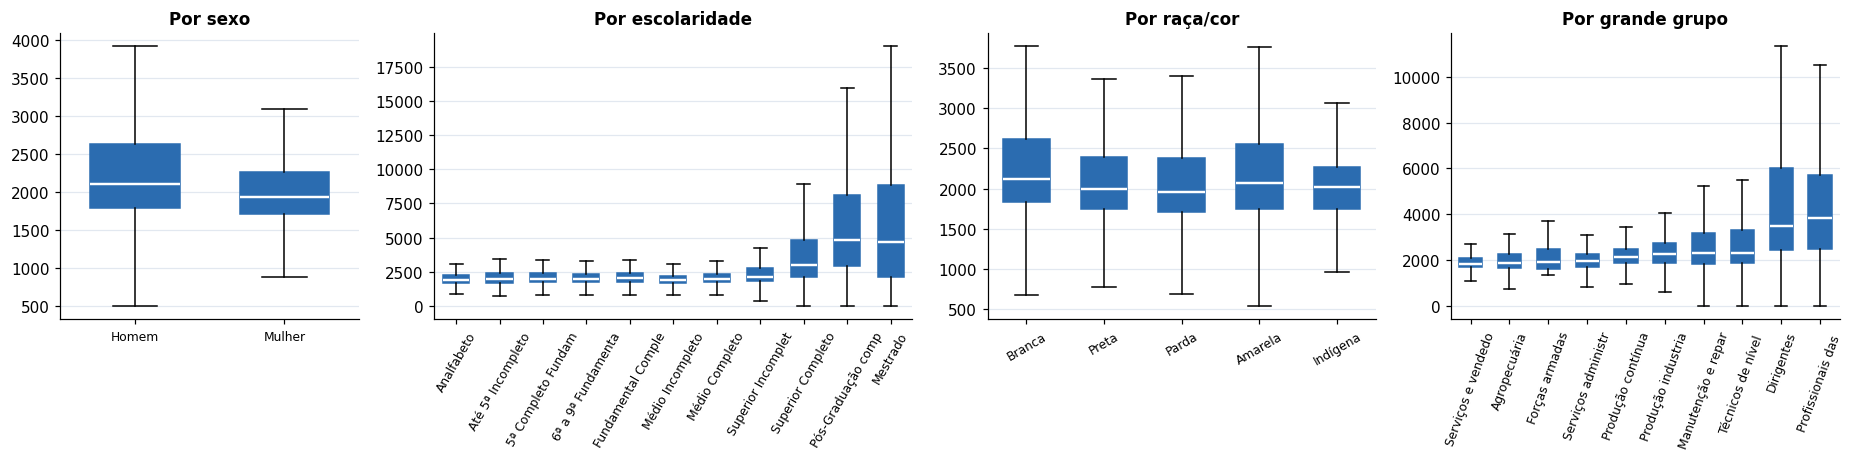

In [37]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4.3), gridspec_kw={"width_ratios": [1, 1.6, 1.3, 1.3]})
d = df[ok]
def caixas(a, chave, ordem, titulo, cor=AZUL, rot=0):
    dados = [d.loc[d[chave] == o, "salário"] for o in ordem]
    bp = a.boxplot(dados, labels=[str(o)[:18] for o in ordem], showfliers=False, patch_artist=True, widths=0.6,
                   medianprops=dict(color="white", lw=1.6))
    for p in bp["boxes"]: p.set(facecolor=cor, edgecolor=cor)
    a.set_title(titulo); a.tick_params(axis="x", rotation=rot, labelsize=8); a.grid(axis="x", visible=False)
caixas(ax[0], "sexo_r", ["Homem", "Mulher"], "Por sexo")
caixas(ax[1], "instrucao", ORD_INSTR[:11], "Por escolaridade", rot=60)
caixas(ax[2], "raca", ["Branca", "Preta", "Parda", "Amarela", "Indígena"], "Por raça/cor", rot=30)
ordem_g = d.groupby("grande_grupo")["salário"].median().sort_values().index.tolist()
caixas(ax[3], "grande_grupo", ordem_g, "Por grande grupo", rot=70)
plt.tight_layout(); plt.show()

In [38]:
# Hiato salarial por sexo: geral e dentro de cada grande grupo (efeito de composição)
med = d.groupby(["grande_grupo", "sexo_r"])["salário"].median().unstack()[["Homem", "Mulher"]]
med["razão M/H"] = med["Mulher"] / med["Homem"]
geral = d.groupby("sexo_r")["salário"].median()
print(f"Mediana geral — Homem: R$ {geral['Homem']:,.0f} | Mulher: R$ {geral['Mulher']:,.0f} | razão M/H = {geral['Mulher']/geral['Homem']:.3f}")
med.sort_values("razão M/H")

Mediana geral — Homem: R$ 2,113 | Mulher: R$ 1,940 | razão M/H = 0.918


sexo_r,Homem,Mulher,razão M/H
grande_grupo,,,
Forças armadas,"2,200.00","1,661.00",0.76
Manutenção e reparação,"2,350.00","1,900.00",0.81
Técnicos de nível médio,"2,530.27","2,176.85",0.86
Dirigentes,"3,700.00","3,250.00",0.88
Profissionais das ciências e artes,"4,134.45","3,672.04",0.89
Produção industrial e construção,"2,302.75","2,050.00",0.89
Produção contínua,"2,189.83","2,072.40",0.95
Agropecuária,"1,890.24","1,804.00",0.95
Serviços administrativos,"2,000.00","1,911.66",0.96


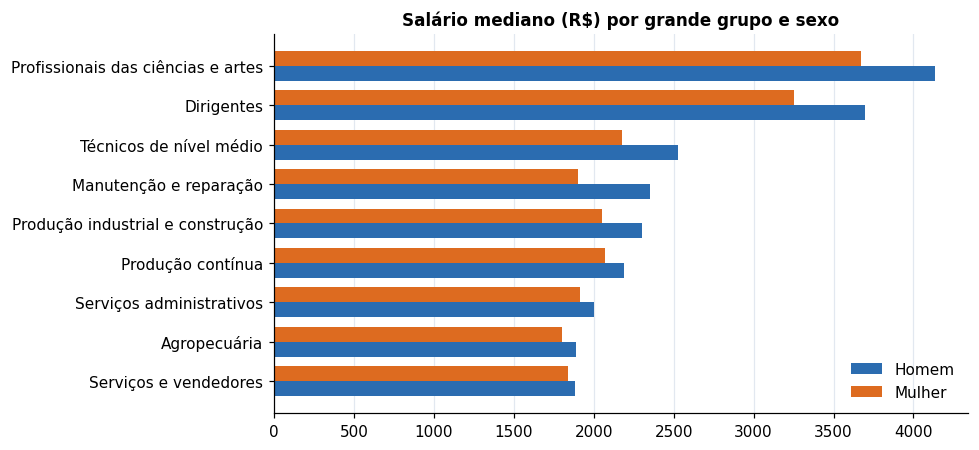

In [39]:
fig, ax = plt.subplots(figsize=(9, 4.2))
m = med.loc[med.index != "Forças armadas"].sort_values("Homem")
y = np.arange(len(m)); w = 0.38
ax.barh(y - w/2, m["Homem"], w, color=AZUL, label="Homem"); ax.barh(y + w/2, m["Mulher"], w, color=LARANJA, label="Mulher")
ax.set_yticks(y, m.index); ax.set_title("Salário mediano (R$) por grande grupo e sexo"); ax.legend(frameon=False)
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

In [40]:
# Concentração no piso: valores mais comuns de salário
vc = df["salário"].value_counts(normalize=True).head(10).mul(100).round(2).rename("%").to_frame()
vc.index.name = "salário (R$)"
print(f"Salário exatamente R$ {PISO:,.0f} (piso do mês): {(df['salário']==PISO).mean():.2%} | até 5% acima do piso: {(df['salário'].between(1, PISO*1.05)).mean():.2%}")
vc

Salário exatamente R$ 1,621 (piso do mês): 6.18% | até 5% acima do piso: 20.29%


,%
salário (R$),
"1,621.00",6.18
"2,000.00",1.56
"1,800.00",1.18
"2,500.00",1.16
0.00,1.12
"2,100.00",1.12
"1,837.40",0.95
"3,000.00",0.82
"1,700.00",0.82


## 15. Cruzamentos entre variáveis qualitativas
Percentuais por linha (cada linha soma 100%).

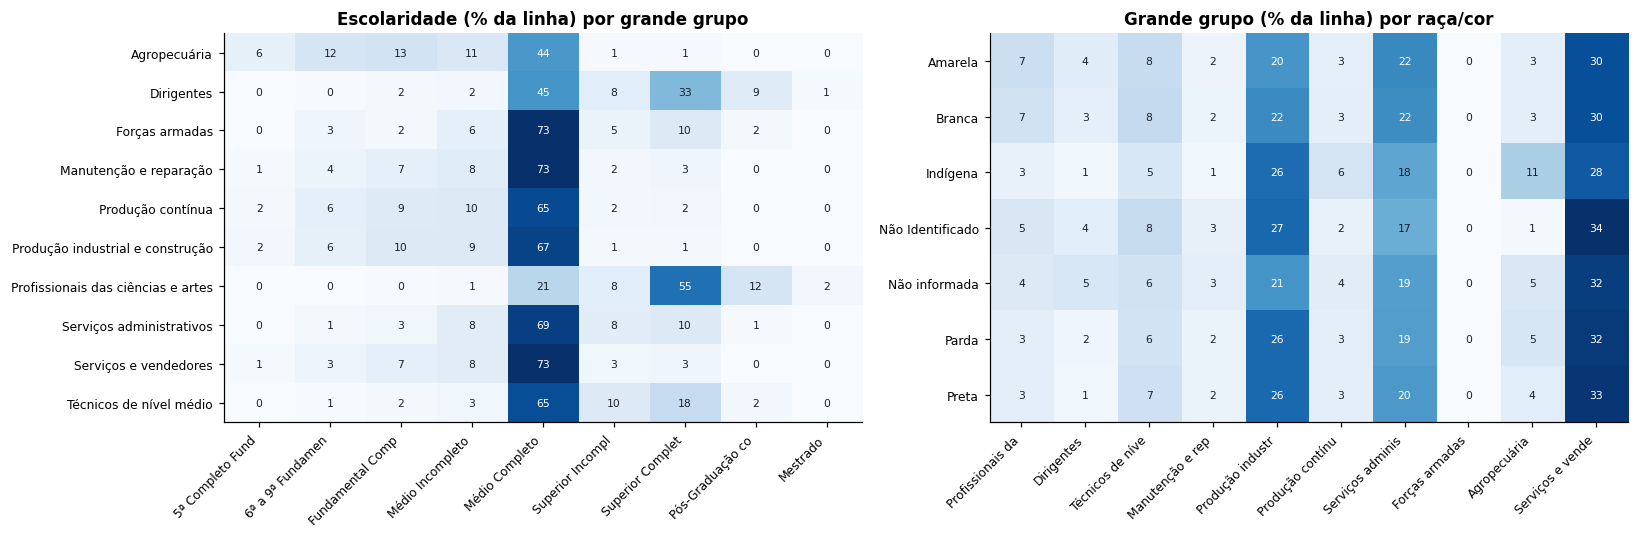

In [41]:
def mapa(ax, tab, titulo, fmt="{:.0f}"):
    ax.imshow(tab.values, cmap="Blues", aspect="auto", vmin=0, vmax=tab.values.max())
    ax.set_xticks(range(tab.shape[1]), [str(c)[:16] for c in tab.columns], rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(tab.shape[0]), [str(i)[:34] for i in tab.index], fontsize=8)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7,
                                          color="white" if v > tab.values.max() * 0.55 else "#1A202C")
    ax.set_title(titulo); ax.grid(False)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
t1 = pd.crosstab(df["grande_grupo"], df["instrucao"], normalize="index")[ORD_INSTR[2:11]] * 100
mapa(ax[0], t1, "Escolaridade (% da linha) por grande grupo")
t2 = pd.crosstab(df["raca"], df["grande_grupo"], normalize="index")[ordem_g[::-1]] * 100
mapa(ax[1], t2, "Grande grupo (% da linha) por raça/cor")
plt.tight_layout(); plt.show()

In [42]:
print("% de cada raça/cor por sexo:")
display((pd.crosstab(df["sexo_r"], df["raca"], normalize="index") * 100).round(1))
print("Escolaridade por sexo (%):")
display((pd.crosstab(df["instrucao"], df["sexo_r"], normalize="columns") * 100).round(1).loc[ORD_INSTR[2:12]])

% de cada raça/cor por sexo:


raca,Amarela,Branca,Indígena,Não Identificado,Não informada,Parda,Preta
sexo_r,,,,,,,
Homem,0.60,35.60,0.40,0.00,0.20,53.30,9.90
Mulher,0.80,42.40,0.30,0.00,0.20,47.40,8.90


Escolaridade por sexo (%):


sexo_r,Homem,Mulher
instrucao,,
5ª Completo Fundamental,1.50,0.70
6ª a 9ª Fundamental,4.60,2.50
Fundamental Completo,7.40,4.70
Médio Incompleto,8.30,6.80
Médio Completo,65.40,66.00
Superior Incompleto,3.20,5.40
Superior Completo,5.70,10.70
Pós-Graduação completa,0.80,1.60
Mestrado,0.10,0.20


## 16. Correlações (Spearman)
Entre idade, horas, escolaridade (rank ordinal) e salário (filtro `ok`).

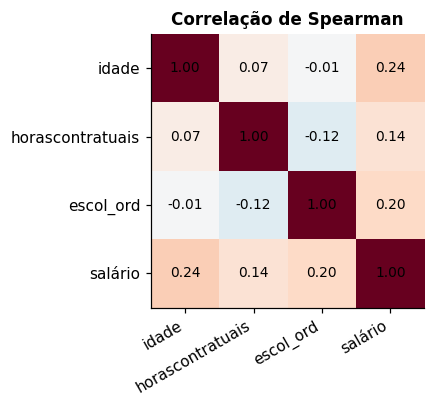

In [43]:
cols = ["idade", "horascontratuais", "escol_ord", "salário"]
cor = df.loc[ok, cols].rank().corr()
fig, ax = plt.subplots(figsize=(4.8, 3.8))
ax.imshow(cor.values, cmap="RdBu_r", vmin=-1, vmax=1)      # divergente: 0 = neutro
ax.set_xticks(range(4), cols, rotation=30, ha="right"); ax.set_yticks(range(4), cols)
for i in range(4):
    for j in range(4): ax.text(j, i, f"{cor.values[i,j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Correlação de Spearman"); ax.grid(False); plt.tight_layout(); plt.show()

## 17. Parâmetros populacionais candidatos
Valores *verdadeiros* na população (a base inteira de setembro/2026), que servirão de referência para comparar com as estimativas amostrais. Ajuste a definição da população antes de usá-los no trabalho.

In [44]:
sal_ok = df.loc[ok, "salário"]
params = pd.DataFrame([
    ("Proporção", "Mulher", df["mulher"].mean(), np.sqrt(df["mulher"].mean() * (1 - df["mulher"].mean()))),
    ("Proporção", "Admissão (saldo = +1)", df["adm"].mean(), np.sqrt(df["adm"].mean() * (1 - df["adm"].mean()))),
    ("Proporção", "Ensino médio completo", (df["graudeinstrução"] == 7).mean(), np.nan),
    ("Proporção", "Raça/cor parda", (df["raçacor"] == 3).mean(), np.nan),
    ("Proporção", "Grande grupo 4 ou 5 (administ./serviços)", df["cbo"].str[0].isin(["4", "5"]).mean(), np.nan),
    ("Média", "Idade (anos)", df["idade"].mean(), df["idade"].std()),
    ("Média", "Horas contratuais semanais", df["horascontratuais"].mean(), df["horascontratuais"].std()),
    ("Média", "Salário (R$), filtro 0<s≤20.000", sal_ok.mean(), sal_ok.std()),
    ("Média", "log10(salário), filtro 0<s≤20.000", np.log10(sal_ok).mean(), np.log10(sal_ok).std()),
], columns=["tipo", "parâmetro", "valor populacional", "desvio-padrão populacional"])
params["valor populacional"] = params["valor populacional"].astype(float)
params

,tipo,parâmetro,valor populacional,desvio-padrão populacional
0,Proporção,Mulher,0.43,0.49
1,Proporção,Admissão (saldo = +1),0.51,0.50
2,Proporção,Ensino médio completo,0.66,NaN
3,Proporção,Raça/cor parda,0.51,NaN
4,Proporção,Grande grupo 4 ou 5 (administ./serviços),0.52,NaN
5,Média,Idade (anos),33.08,11.50
6,Média,Horas contratuais semanais,42.31,5.43
7,Média,"Salário (R$), filtro 0<s≤20.000","2,388.50","1,475.11"
8,Média,"log10(salário), filtro 0<s≤20.000",3.33,0.21


## 18. Prévia da variabilidade amostral (simulação)
**Só exploratório:** nada é salvo. Tamanho amostral clássico para estimar proporção com 95% de confiança, erro de 5% e p = 0,5:

$n = \lceil z^2 \, p(1-p) / e^2 \rceil$. Para a média usaremos a mesma amostra.
Simulamos 2.000 amostras aleatórias (com reposição na prática — a probabilidade de repetir um registro com $n \ll N$ é desprezível) para ver se a distribuição das estimativas é aproximadamente normal e se os ICs de 95% cobrem o parâmetro cerca de 95% das vezes.

n = 385  (z=1.96, e=0.05, p=0.5)


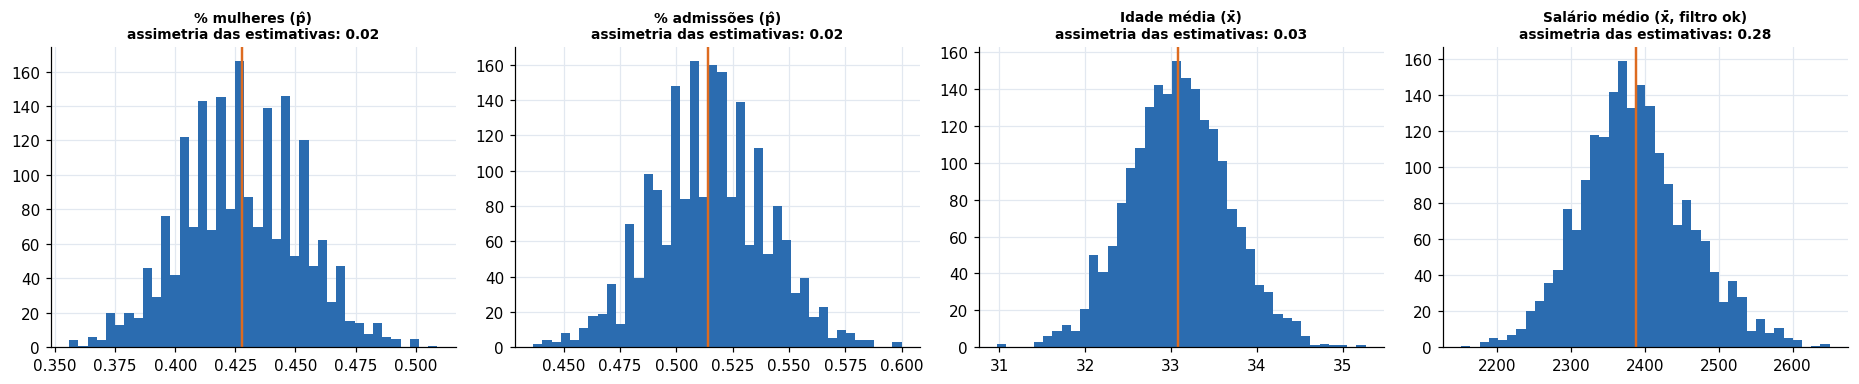

,parâmetro,média das estimativas,EP simulado,cobertura IC 95%
estimador,,,,
% mulheres (p̂),0.43,0.43,0.02,0.95
% admissões (p̂),0.51,0.51,0.03,0.95
Idade média (x̄),33.08,33.09,0.58,0.95
"Salário médio (x̄, filtro ok)","2,388.50","2,387.27",73.89,0.94


In [45]:
from math import ceil
from scipy import stats
z, e, p = 1.96, 0.05, 0.5
n = ceil(z**2 * p * (1 - p) / e**2)
print(f"n = {n}  (z={z}, e={e}, p={p})")

rng = np.random.default_rng(42)
R = 2000
arrs = {
    "% mulheres (p̂)": (df["mulher"].to_numpy().astype(float), "prop"),
    "% admissões (p̂)": (df["adm"].to_numpy().astype(float), "prop"),
    "Idade média (x̄)": (df["idade"].fillna(df["idade"].mean()).to_numpy(), "media"),
    "Salário médio (x̄, filtro ok)": (sal_ok.to_numpy(), "media"),
}
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6)); linhas = []
for a, (nome, (v, tipo)) in zip(ax, arrs.items()):
    mu = v.mean(); idx = rng.integers(0, len(v), size=(R, n)); amo = v[idx]
    xb = amo.mean(axis=1); s = amo.std(axis=1, ddof=1)
    if tipo == "prop": hw = z * np.sqrt(xb * (1 - xb) / n)
    else:              hw = stats.t.ppf(0.975, n - 1) * s / np.sqrt(n)
    cobre = ((xb - hw) <= mu) & (mu <= (xb + hw))
    a.hist(xb, bins=40, color=AZUL); a.axvline(mu, color=LARANJA, lw=1.6)
    a.set_title(f"{nome}\nassimetria das estimativas: {stats.skew(xb):.2f}", fontsize=9)
    linhas.append({"estimador": nome, "parâmetro": mu, "média das estimativas": xb.mean(),
                   "EP simulado": xb.std(), "cobertura IC 95%": cobre.mean()})
plt.tight_layout(); plt.show()
pd.DataFrame(linhas).set_index("estimador")

## 19. Pontos a decidir (resumo)
1. **Mês:** decidido — setembro/2026 (outubro/2025 mantido localmente, fora da análise).
2. **Salário:** truncar a população (ex.: piso ≤ s ≤ teto justificado) ou testar a média do log? Ver seções 5.1 e 18.
3. **Variável de profissão:** usar o **grande grupo** (9–10 categorias) nos painéis e a ocupação específica como filtro.
4. **Unidade amostral:** movimentação (a mesma pessoa pode aparecer mais de uma vez; há ~4,4% de linhas duplicadas) — registrar como limitação.
5. **Hipóteses candidatas** (ver seção 17): proporção de mulheres, proporção de admissões, idade média, salário médio vs. piso do mês (detectado nos dados).